# Module C validation: pitch contour, excitation, synthesis

Runs on repo files only. The vocal tract filter comes from `librosa.lpc` as a stand-in for `src.lpc.lpc_all`.

In [1]:
import sys, os
from pathlib import Path
root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))
import numpy as np, scipy.signal, librosa, soundfile
import matplotlib
import matplotlib.pyplot as plt
from src import pitch, synth
from src.mocks import mock_frames, mock_energy
from tests.fixtures import pseudo_whisper
FS, HOP = 16000, 160
plt.rcParams.update({"figure.figsize": (7, 3), "figure.dpi": 80})

def est_f0(x, lo=70, hi=400):
    x = x - np.mean(x); n = len(x)
    acf = np.fft.irfft(np.abs(np.fft.rfft(x, 2 * n)) ** 2)[:n]
    lags = np.arange(int(FS / hi), int(FS / lo))
    return FS / lags[np.argmax(acf[lags])]

def hop_rms(x):
    n = len(x) // HOP
    return np.sqrt(np.mean(x[:n * HOP].astype(float).reshape(n, HOP) ** 2, axis=1))

x, fs = pseudo_whisper()
frames = mock_frames(x, 320, HOP)
energy = mock_energy(frames)
zcr = np.mean(np.abs(np.diff(np.sign(frames), axis=1)) > 0, axis=1)
labels = np.where(energy < 0.01, 0, np.where(zcr > 0.25, 1, 2))
print(len(frames), "frames, label counts:", np.bincount(labels))

257 frames, label counts: [128  28 101]


## C1 Impulse train

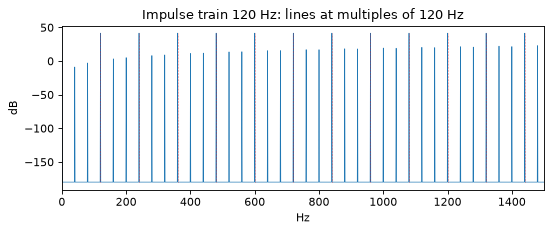

impulses in 1 s: 120


In [2]:
e1 = pitch.impulse_train(120, 1.0, FS)
E = 20 * np.log10(np.abs(np.fft.rfft(e1)) + 1e-9)
fr = np.fft.rfftfreq(len(e1), 1 / FS)
plt.plot(fr, E, lw=0.6); plt.xlim(0, 1500)
plt.vlines(120 * np.arange(1, 13), E.min(), E.max(), colors="r", lw=0.5, ls=":")
plt.xlabel("Hz"); plt.ylabel("dB"); plt.title("Impulse train 120 Hz: lines at multiples of 120 Hz")
plt.tight_layout(); plt.show()
print("impulses in 1 s:", int(e1.sum()))

## C2 Rosenberg glottal pulse

length 133 start 0.0 peak at 0.39849624060150374 of T0


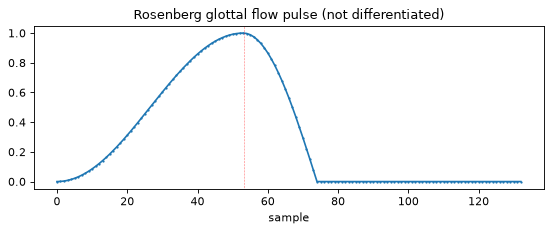

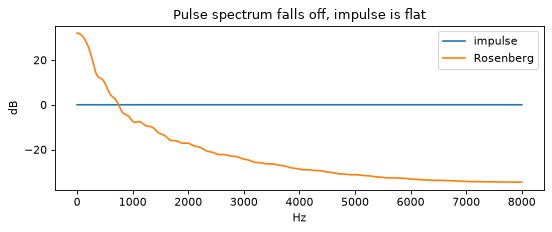

In [3]:
T0 = FS / 120
p = pitch.rosenberg_pulse(T0)
print("length", len(p), "start", p[0], "peak at", np.argmax(p) / len(p), "of T0")
plt.plot(p, ".-", ms=2); plt.axvline(0.4 * len(p), c="r", lw=0.5, ls=":")
plt.title("Rosenberg glottal flow pulse (not differentiated)"); plt.xlabel("sample")
plt.tight_layout(); plt.show()
n = 4096
P = 20 * np.log10(np.abs(np.fft.rfft(p, n)) + 1e-9)
I = 20 * np.log10(np.abs(np.fft.rfft(np.r_[1.0, np.zeros(len(p) - 1)], n)) + 1e-9)
f = np.fft.rfftfreq(n, 1 / FS)
plt.plot(f, I, label="impulse"); plt.plot(f, P, label="Rosenberg"); plt.legend()
plt.xlabel("Hz"); plt.ylabel("dB"); plt.title("Pulse spectrum falls off, impulse is flat")
plt.tight_layout(); plt.show()

## C3 Excitation f0 check

In [4]:
for f0 in (120.0, 200.0):
    e = pitch.make_excitation(np.full(100, 2), np.full(100, f0), HOP, FS)
    est = est_f0(e[HOP * 10:HOP * 70])
    print(f"target {f0:.0f} Hz  estimated {est:.1f} Hz  error {abs(est - f0) / f0 * 100:.2f} %")
g = np.linspace(100, 150, 150)
eg = pitch.make_excitation(np.full(150, 2), g, HOP, FS)
print("glide 100->150: start", round(est_f0(eg[HOP * 5:HOP * 30]), 1), "end", round(est_f0(eg[HOP * 120:HOP * 145]), 1))
r = hop_rms(pitch.make_excitation(np.full(200, 2), np.full(200, 120.0), HOP, FS, aspiration=0.0))[2:]
print("per hop RMS over constant f0 run: min %.3f max %.3f" % (r.min(), r.max()))

target 120 Hz  estimated 120.3 Hz  error 0.25 %
target 200 Hz  estimated 200.0 Hz  error 0.00 %
glide 100->150: start 105.3 end 144.1
per hop RMS over constant f0 run: min 0.912 max 1.161


## C4 f0 contour over a two phrase label track

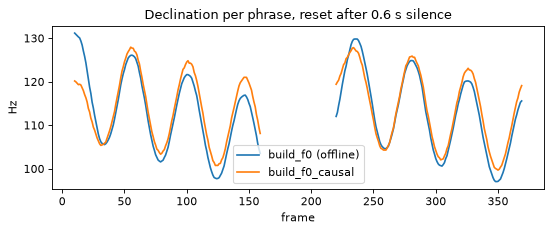

In [5]:
lab2 = np.concatenate([np.zeros(10), np.full(150, 2), np.zeros(60), np.full(150, 2), np.zeros(10)]).astype(int)
en2 = 0.05 * np.exp(0.4 * np.sin(2 * np.pi * np.arange(len(lab2)) / 45))
f0o = pitch.build_f0(lab2, en2)
f0c = pitch.build_f0_causal(lab2, en2)
plt.plot(np.where(f0o > 0, f0o, np.nan), label="build_f0 (offline)")
plt.plot(np.where(f0c > 0, f0c, np.nan), label="build_f0_causal")
plt.xlabel("frame"); plt.ylabel("Hz"); plt.legend(); plt.title("Declination per phrase, reset after 0.6 s silence")
plt.tight_layout(); plt.show()

## C5 Excitation by label

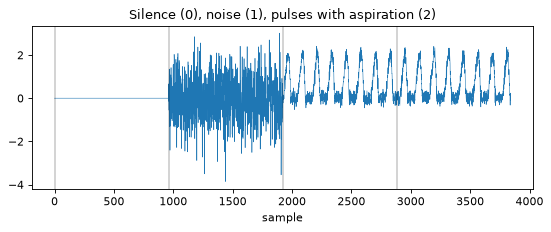

per label hop RMS: {0: 0.0, 1: 1.0, 2: 0.998}


In [6]:
labs = np.repeat([0, 1, 2, 2], 6)
f0s = np.where(labs == 2, 130.0, 0.0)
e5 = pitch.make_excitation(labs, f0s, HOP, FS)
plt.plot(e5, lw=0.5)
for i in range(0, len(labs), 6):
    plt.axvline(i * HOP, c="k", lw=0.3)
plt.title("Silence (0), noise (1), pulses with aspiration (2)"); plt.xlabel("sample")
plt.tight_layout(); plt.show()
print("per label hop RMS:", {l: round(float(np.mean(hop_rms(e5)[labs == l])), 3) for l in (0, 1, 2)})

## C6 Synthesis, waveform across hop boundaries

C:\Users\raksh\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


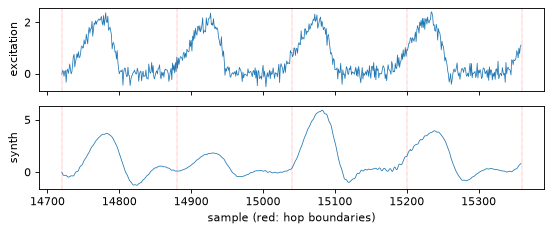

In [7]:
A = np.array([librosa.lpc(f.astype(float), order=12) for f in frames])
G = np.array([np.sqrt(np.mean(scipy.signal.lfilter(a, [1.0], f.astype(float)) ** 2)) + 1e-9 for a, f in zip(A, frames)])
f0 = pitch.build_f0(labels, energy)
e = pitch.make_excitation(labels, f0, HOP, FS)
y_raw = synth.synthesize(A, G, e, labels, energy, HOP)
i = int(np.flatnonzero(labels == 2)[40])
seg = slice(i * HOP - 160, i * HOP + 480)
t = np.arange(seg.start, seg.stop)
fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(t, e[seg], lw=0.7); ax[0].set_ylabel("excitation")
ax[1].plot(t, y_raw[seg], lw=0.7); ax[1].set_ylabel("synth")
for k in range(i - 1, i + 4):
    for a_ in ax: a_.axvline(k * HOP, c="r", lw=0.4, ls=":")
ax[1].set_xlabel("sample (red: hop boundaries)")
plt.tight_layout(); plt.show()

## C7 Output stage: loudness follows input

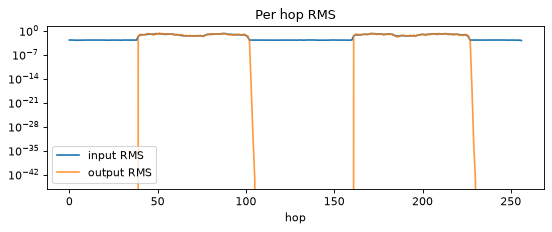

ratio out/in on non-silent hops: min 0.57 max 1.96
corr of log RMS: 0.812
radiation applied once, hop 0 matches lfilter([1,-0.98]): True


In [8]:
y_out = synth.output_stage(y_raw, energy, HOP)
r = hop_rms(y_out)
loud = energy > 0.03
fig, ax = plt.subplots()
ax.plot(energy, label="input RMS"); ax.plot(r, label="output RMS", alpha=0.8)
ax.set_xlabel("hop"); ax.set_yscale("log"); ax.legend(); ax.set_title("Per hop RMS")
plt.tight_layout(); plt.show()
print("ratio out/in on non-silent hops: min %.2f max %.2f" % ((r[loud] / energy[loud]).min(), (r[loud] / energy[loud]).max()))
print("corr of log RMS:", round(float(np.corrcoef(np.log(r[loud]), np.log(energy[loud]))[0, 1]), 3))
st = synth.init_output_state()
j = int(np.flatnonzero(labels == 2)[40]) * HOP
rad = scipy.signal.lfilter([1.0, -0.98], [1.0], y_raw[j:j + HOP].astype(float))
o, st = synth.output_step(y_raw[j:j + HOP].astype(float), 0.1, st)
print("radiation applied once, hop 0 matches lfilter([1,-0.98]):", np.allclose(o, rad * (0.1 / np.sqrt(np.mean(rad ** 2))), rtol=1e-3, atol=1e-6))